# Semana 4: analisis de pedidos de e-commerce

En este notebook se construye un flujo completo de trabajo:

1. Configurar la ruta del proyecto para importar las clases reutilizables.
2. Cargar `e-commerce-orders` desde Hugging Face.
3. Obtener un `DataFrame` de pandas y revisar su estructura.
4. Generar un reporte en pantalla y guardarlo en un archivo `.txt`.

Ejecuta las celdas en orden. Si el dataset requiere autenticacion, inicia sesion previamente con `hf auth login`.

## 1. Preparar el entorno e importar la clase de carga

El notebook puede ejecutarse desde distintas carpetas. Por eso se buscan los directorios padres hasta encontrar `src/clases_po` y se agrega `src` a `sys.path`. Asi se puede importar `HFDatasetLoader` sin instalar el proyecto como paquete.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
while ROOT != ROOT.parent and not (ROOT / "src" / "clases_po").exists():
    ROOT = ROOT.parent

sys.path.insert(0, str(ROOT / "src"))

from clases_po import HFDatasetLoader

c:\Users\Usuario\Documents\Developers\PI3_2026Q4_Mary_Santi_Esteban\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 2. Configurar el dataset y la salida

`dataset_name` identifica el repositorio en Hugging Face y `split="train"` indica la division que se descargara. El parametro `filename` hace que el `DataFrame` tambien se guarde como CSV en `src/sincronicas/datos/` cuando el notebook se ejecuta desde esa carpeta.

In [2]:
loader = HFDatasetLoader(
    dataset_name="millat/e-commerce-orders",
    split="train",
    filename="datos/e-commerce-orders.csv",
)


## 3. Descargar el dataset y crear el DataFrame

El metodo `load()` descarga el dataset, lo convierte a `pandas.DataFrame` y lo asigna a la variable `df`. La expresion `df.head()` muestra las primeras filas para comprobar que la carga fue exitosa.

In [3]:
df = loader.load()
df.head()

,order_id,customer_id,product_id,category,price,quantity,order_date,shipping_date,delivery_status,payment_method,device_type,channel,shipping_address,billing_address,customer_segment
0,b8ec9f86-5919-4b71-a5f7-945e7c0a3db0,2031,845,Books,45.95,4,2024-04-20 14:59:58.897063,2024-04-27 14:59:58.897063,Shipped,PayPal,Mobile,Paid Search,"976 Kevin Station, Davidmouth, Hawaii 92563","38182 Ariel Expressway, Campbellland, Oklahoma...",VIP
1,5ea92c47-c5b2-4bdd-8a50-d77efd77ec89,2350,995,Electronics,403.17,3,2024-04-20 14:59:58.897063,2024-04-22 14:59:58.897063,Delivered,PayPal,Mobile,Paid Search,"72166 Cunningham Crescent, East Nicholasside, ...","38199 Edwin Plain, Johnborough, Maine 81826",Returning
2,5cc48ce0-2c6d-4448-af3f-96f8a910d45b,1818,997,Beauty,317.45,2,2024-04-20 14:59:58.897063,2024-04-27 14:59:58.897063,Shipped,Credit Card,Mobile,Email,"2446 Johnson Junctions, Lynchtown, Minnesota 7...","58086 Smith Stream Suite 994, Lake Pamelabury,...",Returning
3,74d5c0f4-53f0-4367-a5c5-baaa114c2d9f,472,385,Home,24.08,3,2024-04-20 14:59:58.897063,2024-04-24 14:59:58.897063,Shipped,PayPal,Tablet,Social,"3113 Jessica Knolls, North Joshuafort, Alabama...","484 Palmer Harbors Apt. 866, Dustintown, Nebra...",VIP
4,7a630323-8ac8-406e-875a-4bcdead440ab,1075,31,Clothing,494.90,1,2024-04-20 14:59:58.897063,2024-04-25 14:59:58.897063,Delivered,PayPal,Tablet,Organic,"58196 Burgess Heights Suite 315, Douglasland, ...","67094 Schaefer Villages Suite 369, Douglasches...",VIP


In [4]:
df.shape

(10000, 15)

## 4. Revisar la estructura del DataFrame

Esta celda realiza una revision inicial: cuenta filas y columnas y muestra el tipo de cada columna junto con informacion de memoria y valores no nulos. Esta inspeccion ayuda a detectar problemas antes de analizar los datos.

In [5]:
print(f"Filas: {len(df)}")
print(f"Columnas: {len(df.columns)}")
df.info()

Filas: 10000
Columnas: 15
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 15 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   order_id          10000 non-null  str    
 1   customer_id       10000 non-null  int64  
 2   product_id        10000 non-null  int64  
 3   category          10000 non-null  str    
 4   price             10000 non-null  float64
 5   quantity          10000 non-null  int64  
 6   order_date        10000 non-null  str    
 7   shipping_date     10000 non-null  str    
 8   delivery_status   10000 non-null  str    
 9   payment_method    10000 non-null  str    
 10  device_type       10000 non-null  str    
 11  channel           10000 non-null  str    
 12  shipping_address  10000 non-null  str    
 13  billing_address   10000 non-null  str    
 14  customer_segment  10000 non-null  str    
dtypes: float64(1), int64(3), str(11)
memory usage: 3.4 MB


## 1.1 Preparar el entorno e importar las clases

El notebook puede ejecutarse desde distintas carpetas. Por eso se buscan los directorios padres hasta encontrar `src/clases_po` y se agrega `src` a `sys.path`. Asi se pueden importar las clases sin instalar el proyecto como paquete.

In [6]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
while ROOT != ROOT.parent and not (ROOT / "src" / "clases_po").exists():
    ROOT = ROOT.parent

sys.path.insert(0, str(ROOT / "src"))

from clases_po import (
    HFDatasetLoader, Reportes, PreprocesadorEcommerce,
    EnriquecedorEcommerce, AnalisisBase, GraficosEcommerce,
)

import pandas as pd
from IPython.display import display

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)


## 1.2 Configurar el dataset y la salida

`dataset_name` identifica el repositorio en Hugging Face y `split="train"` indica la division que se descargara. El parametro `filename` hace que el `DataFrame` tambien se guarde como CSV en `src/sincronicas/datos/` cuando el notebook se ejecuta desde esa carpeta.

In [7]:
loader = HFDatasetLoader(
    dataset_name="millat/e-commerce-orders",
    split="train",
    filename="datos/e-commerce-orders.csv",
)

---
# PARTE 2  Preprocesamiento y estandarizacion (clase `PreprocesadorEcommerce`)

El dataset contiene 10.000 pedidos del periodo disponible en Hugging Face. Se procesa completo para que las conclusiones representen el negocio de e-commerce y no una muestra artificial.

## 2.1 Diagnostico de tipos (hoja **Tipos**, seccion A)

Equivale a `ESTEXTO`, `ESNUMERO`, `CONTARA` y `CONTAR` por columna.

In [8]:
pre = PreprocesadorEcommerce(filas_clase=48620)

df_base = pre.recortar(df)
pre.diagnosticar(df_base)

,columna,tipo_actual,ejemplo,no_vacíos (CONTARA),convertibles_a_número,¿es número? (ESNUMERO)
0,order_id,str,b8ec9f86-5919-4b71-a5f7-945e7c0a3db0,10000,0,False
1,customer_id,int64,2031,10000,10000,True
2,product_id,int64,845,10000,10000,True
3,category,str,Books,10000,0,False
4,price,float64,45.95,10000,10000,True
5,quantity,int64,4,10000,10000,True
6,order_date,str,2024-04-20 14:59:58.897063,10000,0,False
7,shipping_date,str,2024-04-27 14:59:58.897063,10000,0,False
8,delivery_status,str,Shipped,10000,0,False
9,payment_method,str,PayPal,10000,0,False


**Lectura:** fecha y hora llegan como **texto** (y la fecha mezcla `1/1/2015` con `13-01-2015`), los identificadores como decimales (`1.0`), y dispositivo y categoria como texto libre.

## 2.2 Diccionario de columnas (hoja **Tipos**, seccion B)

In [9]:
pre.diccionario()

,columna,qué significa,tipo de variable,tipo en pandas
0,order_id,Identificador único del pedido,Cualitativa nominal,string
1,customer_id,Identificador del cliente,Cuantitativa discreta,int64
2,product_id,Identificador del producto,Cuantitativa discreta,int64
3,quantity,Cantidad de unidades,Cuantitativa discreta,int64
4,order_date,Fecha y hora del pedido,Cuantitativa (tiempo),datetime64
5,shipping_date,Fecha y hora del envío,Cuantitativa (tiempo),datetime64
6,price,Precio unitario,Cuantitativa continua,"float64 (moneda, 2 dec.)"
7,order_value,Cantidad × precio unitario,Cuantitativa continua,"float64 (moneda, 2 dec.)"
8,device_type,Dispositivo utilizado,Cualitativa nominal,category
9,category,Categoría del producto,Cualitativa nominal,category


## 2.3 Convertir tipos y agregar columnas calculadas (hojas **Tipos** D-E y **Datos**)

| Excel | Metodo de la clase |
|---|---|
| `VALOR.NUMERO`, `SUSTITUIR` + `FECHA`, `HORANUMERO`, formato Texto | `convertir_tipos()` |
| `total_calculado`, `verificacion`, `dia_semana`, `hora`, `nuevo_pedido` | `agregar_columnas_calculadas()` |
| Los dos pasos seguidos | `procesar()` |

In [10]:
datos = pre.procesar(df)
datos.head()

,order_id,customer_id,product_id,category,price,quantity,order_date,shipping_date,delivery_status,payment_method,device_type,channel,shipping_address,billing_address,customer_segment,order_time,fecha_hora,shipping_days,order_value,total_calculado,verificacion,dia_semana,hora,nuevo_pedido
0,b8ec9f86-5919-4b71-a5f7-945e7c0a3db0,2031,845,Books,45.95,4,2024-04-20 14:59:58.897063,2024-04-27 14:59:58.897063,Shipped,PayPal,Mobile,Paid Search,"976 Kevin Station, Davidmouth, Hawaii 92563","38182 Ariel Expressway, Campbellland, Oklahoma...",VIP,14:59:58.897063,2024-04-20 14:59:58.897063,7.0,183.80,183.80,OK,sábado,14,1
1,5ea92c47-c5b2-4bdd-8a50-d77efd77ec89,2350,995,Electronics,403.17,3,2024-04-20 14:59:58.897063,2024-04-22 14:59:58.897063,Delivered,PayPal,Mobile,Paid Search,"72166 Cunningham Crescent, East Nicholasside, ...","38199 Edwin Plain, Johnborough, Maine 81826",Returning,14:59:58.897063,2024-04-20 14:59:58.897063,2.0,1209.51,1209.51,OK,sábado,14,1
2,5cc48ce0-2c6d-4448-af3f-96f8a910d45b,1818,997,Beauty,317.45,2,2024-04-20 14:59:58.897063,2024-04-27 14:59:58.897063,Shipped,Credit Card,Mobile,Email,"2446 Johnson Junctions, Lynchtown, Minnesota 7...","58086 Smith Stream Suite 994, Lake Pamelabury,...",Returning,14:59:58.897063,2024-04-20 14:59:58.897063,7.0,634.90,634.90,OK,sábado,14,1
3,74d5c0f4-53f0-4367-a5c5-baaa114c2d9f,472,385,Home,24.08,3,2024-04-20 14:59:58.897063,2024-04-24 14:59:58.897063,Shipped,PayPal,Tablet,Social,"3113 Jessica Knolls, North Joshuafort, Alabama...","484 Palmer Harbors Apt. 866, Dustintown, Nebra...",VIP,14:59:58.897063,2024-04-20 14:59:58.897063,4.0,72.24,72.24,OK,sábado,14,1
4,7a630323-8ac8-406e-875a-4bcdead440ab,1075,31,Clothing,494.90,1,2024-04-20 14:59:58.897063,2024-04-25 14:59:58.897063,Delivered,PayPal,Tablet,Organic,"58196 Burgess Heights Suite 315, Douglasland, ...","67094 Schaefer Villages Suite 369, Douglasches...",VIP,14:59:58.897063,2024-04-20 14:59:58.897063,5.0,494.90,494.90,OK,sábado,14,1


In [11]:
datos.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 24 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   order_id          10000 non-null  string        
 1   customer_id       10000 non-null  Int64         
 2   product_id        10000 non-null  Int64         
 3   category          10000 non-null  category      
 4   price             10000 non-null  float64       
 5   quantity          10000 non-null  int64         
 6   order_date        10000 non-null  datetime64[us]
 7   shipping_date     10000 non-null  datetime64[us]
 8   delivery_status   10000 non-null  string        
 9   payment_method    10000 non-null  string        
 10  device_type       10000 non-null  category      
 11  channel           10000 non-null  string        
 12  shipping_address  10000 non-null  string        
 13  billing_address   10000 non-null  string        
 14  customer_segment  10000 non-null  

## 2.4 Validaciones de calidad

In [12]:
pre.validar(datos)

✔ Sin valores nulos tras convertir 
✔ Sin filas duplicadas 
✔ order_value = quantity × price (0 filas a revisar)
✔ Fechas válidas de pedido y envío 

Rango de fechas: 20/04/2024 a 19/04/2025 (365 días; el último tiene 27 líneas)


True

AB = AnalisisBase(datos, producto_elegido=1, dias_incompletos=[])
GB = GraficosEcommerce(AB)
print("Periodo analizado:", AB.periodo())


In [13]:
AB = AnalisisBase(datos, producto_elegido=1, dias_incompletos=[])
GB = GraficosEcommerce(AB)
print("Periodo analizado:", AB.periodo())


Periodo analizado: 20/04/2024 a 19/04/2025 (365 días)


## 3.1 Formulas basicas (hoja **Formulas**)

Cada formula del Excel con su equivalente en pandas y el resultado: operaciones con la fila 185 (3 Spicy Italian), funciones de resumen, valores unicos y una condicion.

In [14]:
AB.formulas_basicas(fila_excel=185)

,#,qué quiero saber,fórmula en Excel,equivalente en pandas,resultado
0,1,Multiplicar: total de la línea,=Datos!D185*Datos!G185,V.quantity[i] * V.price[i],207.01
1,2,Dividir: precio de cada producto,=Datos!H185/Datos!D185,V.order_value[i] / V.quantity[i],207.01
2,3,Sumar: productos en dos líneas,=Datos!D185+Datos!D186,V.quantity[i] + V.quantity[i+1],3.0
3,4,Restar: precio más alto − más bajo,=MAX(G)-MIN(G),V.price.max() - V.price.min(),494.87
4,5,Redondear el precio promedio,=REDONDEAR(PROMEDIO(G);2),"round(V.price.mean(), 2)",252.55
5,6,Ventas totales,=SUMA(H),V.order_value.sum(),5334932.86
6,7,Unidades vendidas,=SUMA(D),V.quantity.sum(),21247.0
7,8,Líneas con número,=CONTAR(H),V.order_value.count(),10000.0
8,9,Líneas con nombre de producto,=CONTARA(L),V.product_id.notna().sum(),10000.0
9,10,Celdas vacías en la categoría,=CONTAR.BLANCO(J),V.category.isna().sum(),0.0


## 3.2 Resumen del negocio (hoja **Descriptiva**, seccion A)

In [35]:
resumen_ecommerce = pd.Series({
    "Pedidos": datos["order_id"].nunique(),
    "Unidades vendidas": datos["quantity"].sum(),
    "Ventas totales": datos["order_value"].sum(),
    "Venta promedio por pedido": datos["order_value"].mean(),
    "Pedido promedio en unidades": datos["quantity"].mean(),
    "Fecha inicial": datos["order_date"].min().date(),
    "Fecha final": datos["order_date"].max().date(),
    "Clientes únicos": datos["customer_id"].nunique(),
})

display(resumen_ecommerce.to_frame("Valor"))

,Valor
Pedidos,10000
Unidades vendidas,21247
Ventas totales,5334932.86
Venta promedio por pedido,533.493286
Pedido promedio en unidades,2.1247
Fecha inicial,2024-04-20
Fecha final,2025-04-19
Clientes únicos,2713


## 3.3 Medidas de las variables cuantitativas

In [36]:
display(AB.medidas_variables().round(3))
print(AB.lectura_media_mediana())

,quantity,price,order_value,valor_pedido
n (datos),10000.000,10000.000,10000.000,10000.000
Suma,21247.000,2525506.810,5334932.860,5334932.860
Media,2.125,252.551,533.493,533.493
Mediana,2.000,252.910,395.625,395.625
Moda,1.000,65.510,226.530,226.530
Mínimo,1.000,5.060,5.100,5.100
Máximo,9.000,499.930,4224.240,4224.240
Rango,8.000,494.870,4219.140,4219.140
Desviación estándar,1.254,141.394,465.566,465.566
Coef. de variación,0.590,0.560,0.873,0.873


Lectura: en order_value la media ($533.49) es mayor que la mediana ($395.62): unas pocas líneas con varias productos jalan el promedio hacia arriba (sesgo a la derecha).


## 3.4 Frecuencias por dispositivo y por categoria (hoja **Descriptiva**, secciones C y D)  Graficos 3, 4 y 5

Por dispositivo (variable ordinal: S < M < L < XL)


,líneas,% líneas,% acumulado,productos,ventas,% ventas,precio_unit_promedio
Mobile,"3,278",32.8%,32.8%,"6,926","$1,740,201.96",32.6%,$251.44
Tablet,"3,339",33.4%,66.2%,"7,096","$1,768,153.28",33.1%,$251.90
Desktop,"3,383",33.8%,100.0%,"7,225","$1,826,577.62",34.2%,$254.27
Total,"10,000",100.0%,—,"21,247","$5,334,932.86",100.0%,$252.55


Por categoria (variable nominal)


,líneas,% líneas,% acumulado,productos,ventas,% ventas,precio_unit_promedio
Beauty,"1,682",16.8%,16.8%,"3,617","$888,823.19",16.7%,$247.65
Books,"1,625",16.2%,33.1%,"3,404","$862,484.56",16.2%,$255.34
Clothing,"1,620",16.2%,49.3%,"3,392","$863,629.45",16.2%,$256.39
Electronics,"1,694",16.9%,66.2%,"3,586","$910,153.11",17.1%,$255.77
Home,"1,713",17.1%,83.3%,"3,696","$921,394.85",17.3%,$250.30
Toys,"1,666",16.7%,100.0%,"3,552","$888,447.70",16.7%,$250.09
Total,"10,000",100.0%,—,"21,247","$5,334,932.86",100.0%,$252.55


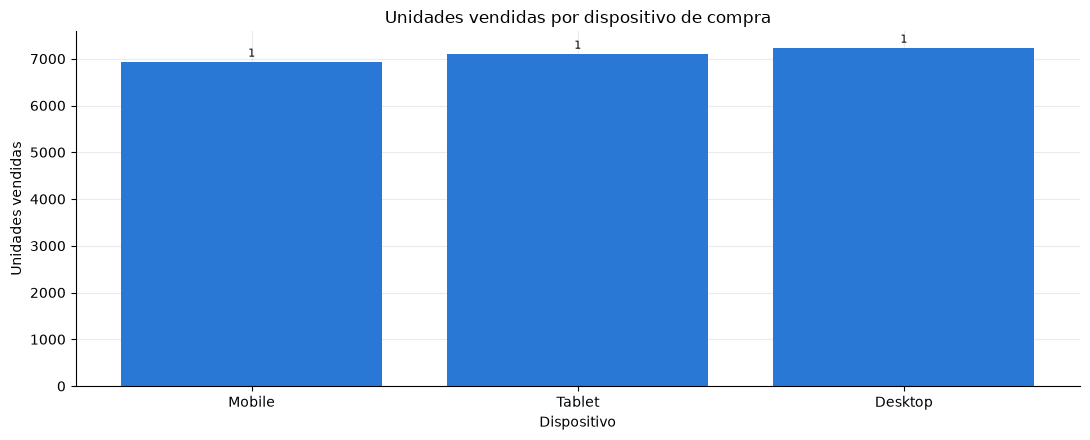

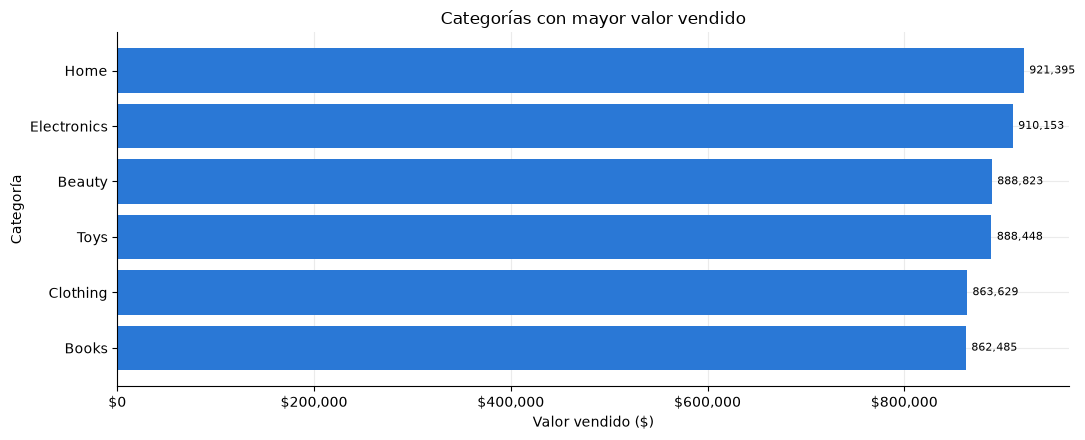

In [ ]:
print("Frecuencias por dispositivo")
display(AB.estilo(AB.frecuencias("device_type")))

print("Frecuencias por categoría")
display(AB.estilo(AB.frecuencias("category")))

GB.dispositivos()
GB.categorias()

## 3.5 Distribucion de `order_value`

,líneas,% líneas
order_value,,
$0 o más,"1,146",11.5%
$100 o más,"1,278",12.8%
$200 o más,"1,283",12.8%
$300 o más,"1,362",13.6%
$400 o más,"1,296",13.0%
$500 o más,"3,635",36.4%


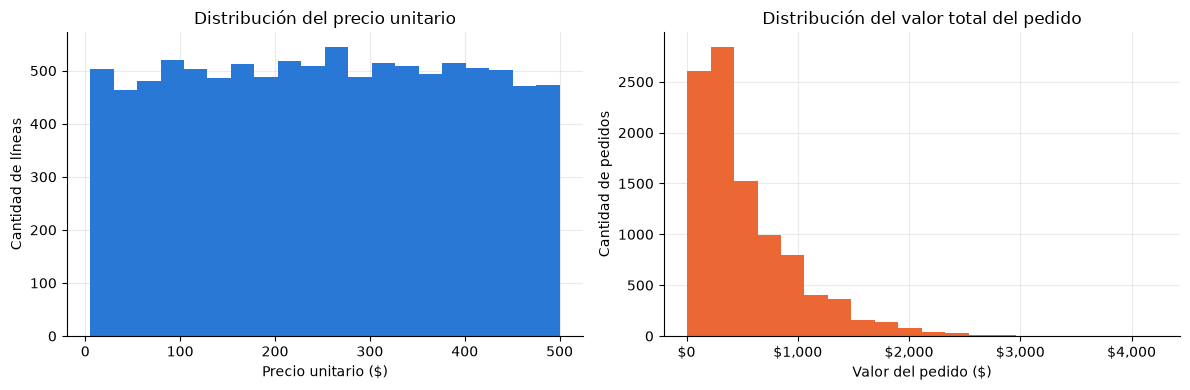

In [18]:
display(AB.estilo(AB.distribucion_precio()))
GB.histogramas()

## 3.6 Ventas por dia y producto seleccionado (hoja **Relaciones**, seccion A)  Graficos 1 y 2

El producto seleccionado (como la lista desplegable del Excel): `AB.producto_elegida = "un identificador de producto"`.

,order_date,día,líneas,productos,pedidos,ventas,ticket promedio,% ventas,ventas producto elegido
0,20/04/2024,sábado,29,56,29,"$10,622.56",$366.30,0.2%,$0.00
1,21/04/2024,domingo,29,75,29,"$20,477.08",$706.11,0.4%,$0.00
2,22/04/2024,lunes,39,83,39,"$16,417.46",$420.96,0.3%,$0.00
3,23/04/2024,martes,23,47,23,"$10,129.70",$440.42,0.2%,$0.00
4,24/04/2024,miércoles,29,62,29,"$16,700.75",$575.89,0.3%,$0.00
5,25/04/2024,jueves,32,70,32,"$16,007.24",$500.23,0.3%,$540.66
6,26/04/2024,viernes,38,77,38,"$20,501.45",$539.51,0.4%,$0.00
7,27/04/2024,sábado,32,54,32,"$10,704.87",$334.53,0.2%,$0.00
8,28/04/2024,domingo,32,69,32,"$18,444.98",$576.41,0.3%,$0.00
9,29/04/2024,lunes,25,50,25,"$14,220.66",$568.83,0.3%,$0.00


Día con más ventas: 12/08/2024 (lunes) → $24,764.74
Día con menos ventas: 21/11/2024 (jueves) → $5,475.59
1: ventas $6,713.81; su mejor día 03/02/2025


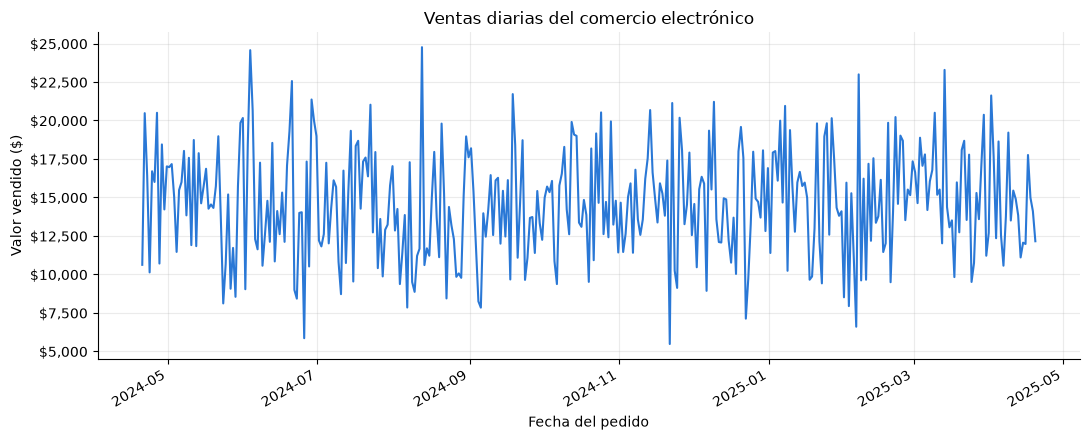

In [19]:
display(AB.estilo(AB.ventas_por_dia().reset_index().assign(order_date=lambda x: x["order_date"].dt.strftime("%d/%m/%Y"))))
print(AB.lectura_dias(excluir_ultimo_incompleto=False))
GB.ventas_por_dia()

Venta promedio por dia de la semana (sin excluir fechas, porque el dataset de e-commerce se analiza completo)


,días en el periodo,ventas,venta promedio por día
dia_semana,,,
lunes,52,"$779,608.29","$14,992.47"
martes,52,"$753,413.59","$14,488.72"
miércoles,52,"$761,386.10","$14,642.04"
jueves,52,"$776,706.80","$14,936.67"
viernes,52,"$769,844.55","$14,804.70"
sábado,53,"$740,206.99","$13,966.17"
domingo,52,"$753,766.54","$14,495.51"


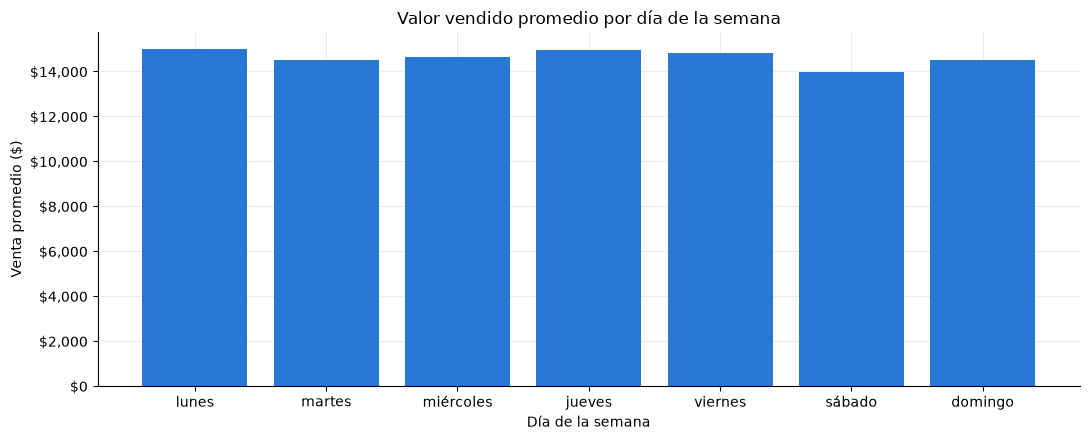

In [20]:
print("Venta promedio por dia de la semana (sin excluir fechas, porque el dataset de e-commerce se analiza completo)")
display(AB.estilo(AB.dia_semana_resumen()))
GB.dia_semana()

## 3.7 Dos categorias a la vez: categoria  dispositivo (hoja **Relaciones**, seccion B)  Grafico 6

,ventas Mobile,ventas Tablet,ventas Desktop,ventas Total
category,,,,
Beauty,"$293,857.84","$293,434.96","$301,530.39","$888,823.19"
Books,"$275,839.59","$295,641.44","$291,003.53","$862,484.56"
Clothing,"$289,667.30","$281,209.12","$292,753.03","$863,629.45"
Electronics,"$269,226.53","$306,598.90","$334,327.68","$910,153.11"
Home,"$316,523.57","$299,966.11","$304,905.17","$921,394.85"
Toys,"$295,087.13","$291,302.75","$302,057.82","$888,447.70"
Total,"$1,740,201.96","$1,768,153.28","$1,826,577.62","$5,334,932.86"


device_type,Mobile,Tablet,Desktop,Total
category,,,,
Beauty,556,548,578,1682
Books,515,553,557,1625
Clothing,538,538,544,1620
Electronics,525,568,601,1694
Home,590,573,550,1713
Toys,554,559,553,1666
Total,3278,3339,3383,10000


Lectura: la combinación que más vende es Electronics Desktop ($334,327.68).


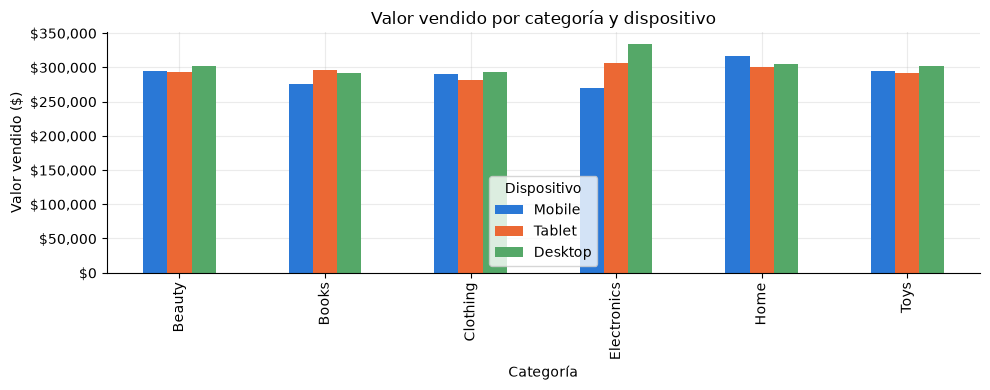

In [21]:
display(AB.estilo(AB.categoria_x_dispositivo("ventas")))
display(AB.categoria_x_dispositivo("lineas"))
print(AB.combinacion_lider())
GB.categoria_dispositivo()


## 3.8 Tres condiciones: un dia, una categoria y un dispositivo

In [22]:
fecha = str(datos["order_date"].min().date())
pd.DataFrame({
    "fecha inicial - Electronics - Mobile": AB.consulta(fecha=fecha, categoria="Electronics", dispositivo="Mobile"),
    "fecha inicial - Home - Desktop": AB.consulta(fecha=fecha, categoria="Home", dispositivo="Desktop"),
    "fecha inicial - Books - Tablet": AB.consulta(fecha=fecha, categoria="Books", dispositivo="Tablet"),
})


,fecha inicial - Electronics - Mobile,fecha inicial - Home - Desktop,fecha inicial - Books - Tablet
Ventas,0.0,0.0,0.0
Unidades,0,0,0
Líneas,0,0,0
Precio promedio,No hubo ventas,No hubo ventas,No hubo ventas


## 3.9 Ventas por hora

,líneas,ventas,% ventas
hora,,,
14,"10,000","$5,334,932.86",100.0%


Hora pico: 14:00


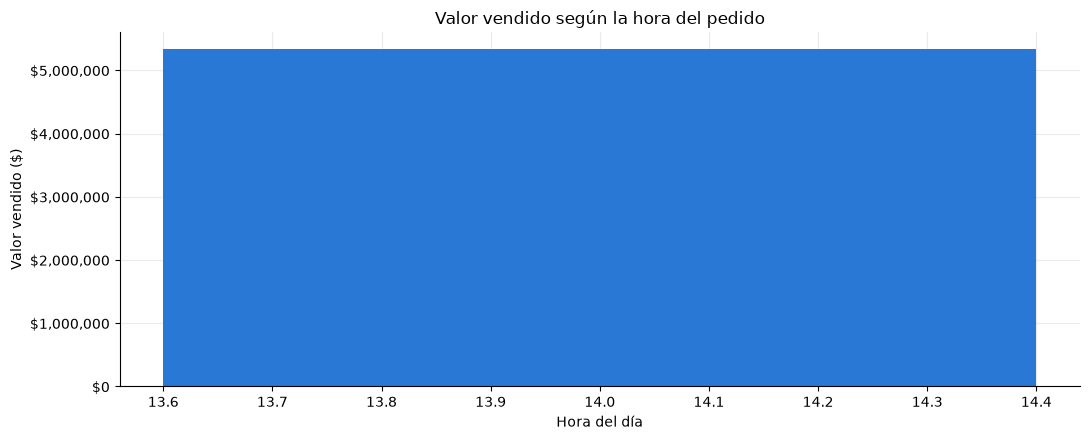

In [23]:
display(AB.estilo(AB.ventas_por_hora()))
print(f"Hora pico: {AB.ventas_por_hora()['ventas'].idxmax()}:00")
GB.ventas_hora()

## 3.10 Ranking de productos por ventas

,posición,categoría,productos,ventas,% ventas,% acumulado
product_id,,,,,,
995,1,Electronics,47,"$15,610.51",0.3%,0.3%
730,2,Toys,50,"$13,774.48",0.3%,0.6%
955,3,Home,43,"$13,480.56",0.3%,0.8%
585,4,Books,37,"$13,397.68",0.3%,1.1%
370,5,Beauty,48,"$13,234.77",0.2%,1.3%
957,6,Toys,42,"$13,012.81",0.2%,1.5%
803,7,Electronics,46,"$12,709.85",0.2%,1.8%
974,8,Electronics,45,"$12,566.78",0.2%,2.0%
642,9,Clothing,49,"$12,287.90",0.2%,2.3%


Pareto: 653 de 999 productos generan el 80 % de las ventas.


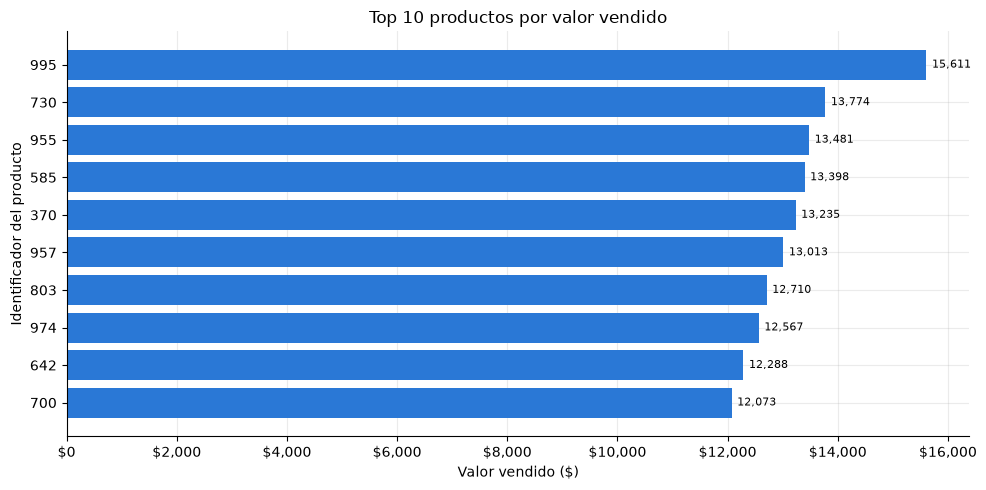

In [24]:
ranking_base = AB.ranking_productos()
display(AB.estilo(ranking_base))
print(f"Pareto: {AB.productos_para_80()} de {len(ranking_base)} productos generan el 80 % de las ventas.")
GB.top_productos(10)


## 3.11 Tabla dinamica

In [25]:
print("Filtro dia_semana: - all -")
display(AB.estilo(AB.tabla_dinamica()))
print("Filtro dia_semana: sabado")
AB.estilo(AB.tabla_dinamica(dia_semana="sabado"))

Filtro dia_semana: - all -


,suma Mobile,suma Tablet,suma Desktop,suma Total
category,,,,
Beauty,"$293,857.84","$293,434.96","$301,530.39","$888,823.19"
Books,"$275,839.59","$295,641.44","$291,003.53","$862,484.56"
Clothing,"$289,667.30","$281,209.12","$292,753.03","$863,629.45"
Electronics,"$269,226.53","$306,598.90","$334,327.68","$910,153.11"
Home,"$316,523.57","$299,966.11","$304,905.17","$921,394.85"
Toys,"$295,087.13","$291,302.75","$302,057.82","$888,447.70"
Total,"$1,740,201.96","$1,768,153.28","$1,826,577.62","$5,334,932.86"


Filtro dia_semana: sabado


category


## 3.12 Dashboard 

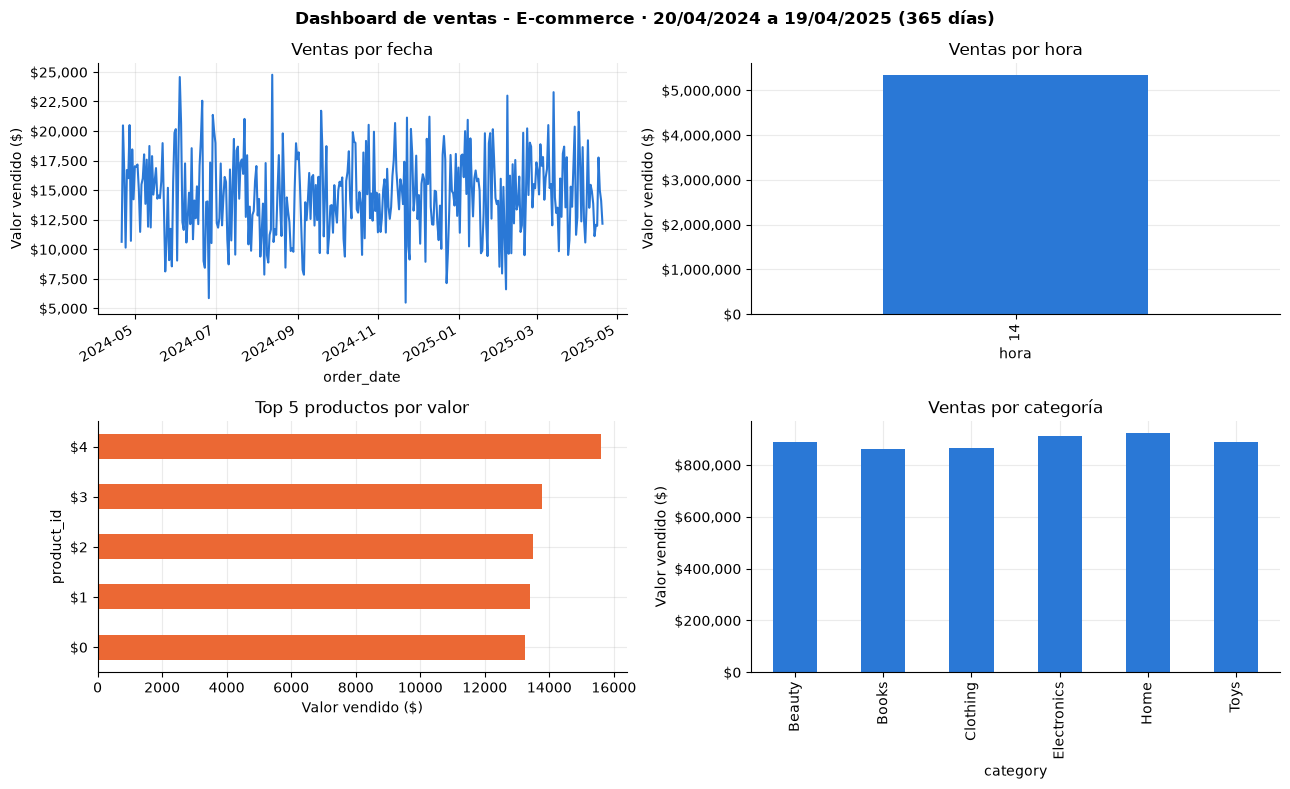

{'VENTAS': '$5,334,932.86',
 'PRODUCTOS': '21,247',
 'PEDIDOS': '10,000',
 'CLIENTES': '2,713',
 'PRECIO PROM./PRODUCTO': '$251.09',
 '% VENTAS TOTALES': '100.0%',
 'MEJOR DÍA': '12/08',
 'HORA PICO': '14:00',
 'PRODUCTO LÍDER': '995'}

In [26]:
GB.dashboard(titulo="Dashboard de ventas - E-commerce")


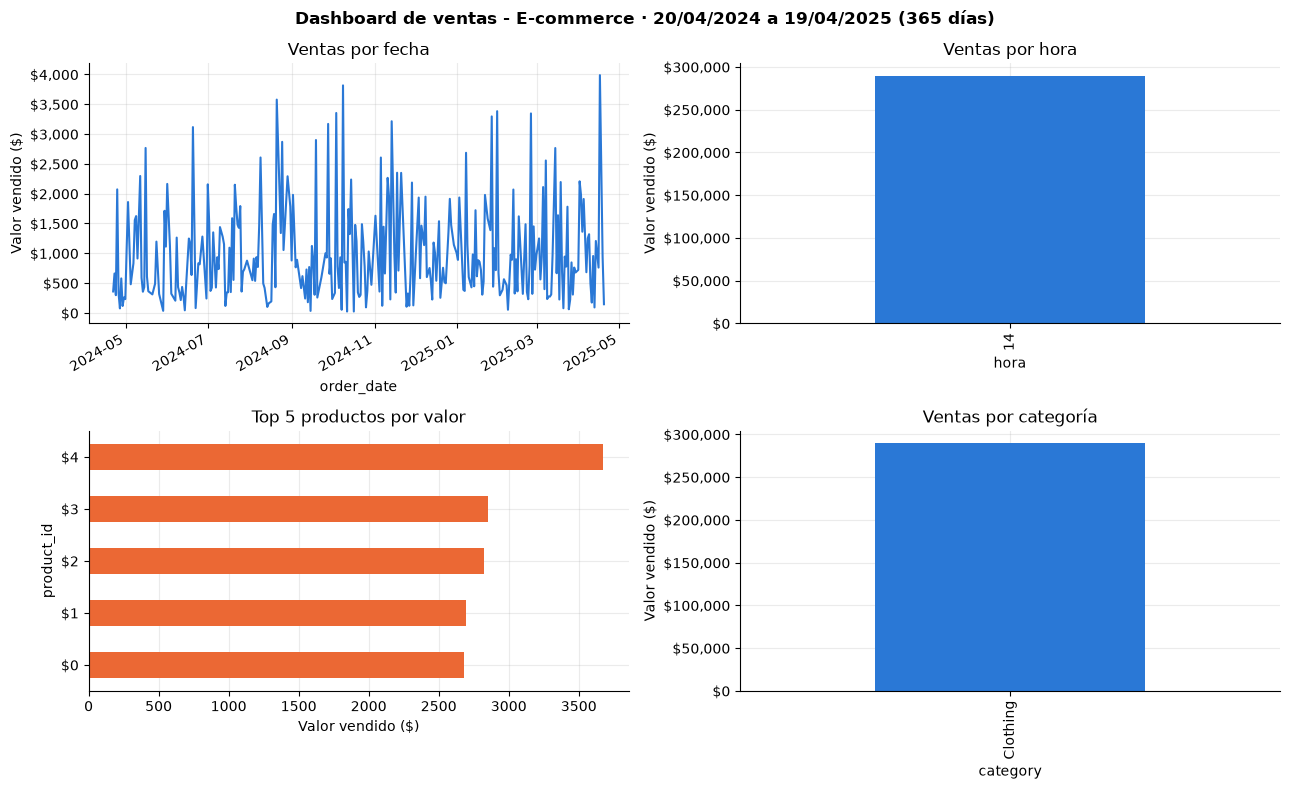

{'VENTAS': '$289,667.30',
 'PRODUCTOS': '1,131',
 'PEDIDOS': '538',
 'CLIENTES': '467',
 'PRECIO PROM./PRODUCTO': '$256.12',
 '% VENTAS TOTALES': '5.4%',
 'MEJOR DÍA': '16/04',
 'HORA PICO': '14:00',
 'PRODUCTO LÍDER': '640'}

In [27]:
GB.dashboard(categoria="Clothing", dispositivo="Mobile", titulo="Dashboard de ventas - E-commerce")


---
# PARTE 4 - Respuestas a las preguntas de negocio

Se conservan los analisis y graficos de la actividad. Esta parte agrega las cuatro preguntas de negocio, con agrupaciones, tablas, interpretaciones, limitaciones y exportaciones reutilizables.

In [28]:
SALIDA_PUNTO_4 = ROOT / "src" / "sincronicas" / "datos" / "resultados_punto_4"
SALIDA_PUNTO_4.mkdir(parents=True, exist_ok=True)
enriquecedor = EnriquecedorEcommerce()
datos_enriquecidos = enriquecedor.enriquecer(datos)
datos_enriquecidos.to_csv(SALIDA_PUNTO_4 / "dataset_ecommerce_preparado.csv", index=False, encoding="utf-8-sig")
Reportes().guardar_reporte(datos_enriquecidos, SALIDA_PUNTO_4 / "resumen_dataset_ecommerce.txt")
print(f"Dataset preparado: {datos_enriquecidos.shape[0]:,} filas y {datos_enriquecidos.shape[1]} columnas")

Dataset preparado: 10,000 filas y 29 columnas


## 4.1 ?Que categorias aportan mas ventas?

**Nivel:** categoria. Se comparan pedidos, unidades, ventas y participacion. **Interpretacion:** orienta inventario y promociones. **Limitacion:** no permite afirmar rentabilidad porque no hay costos.

In [29]:
tabla_categorias = (datos_enriquecidos.groupby("category", observed=True)
    .agg(pedidos=("order_id", "nunique"), unidades=("quantity", "sum"), ventas=("order_value", "sum"))
    .reset_index().sort_values("ventas", ascending=False))
tabla_categorias["participacion_ventas"] = tabla_categorias["ventas"] / tabla_categorias["ventas"].sum()
assert abs(tabla_categorias["participacion_ventas"].sum() - 1) < 1e-9
tabla_categorias.to_csv(SALIDA_PUNTO_4 / "pregunta_1_categorias.csv", index=False, encoding="utf-8-sig")
display(AB.estilo(tabla_categorias))
print(f"Respuesta: {tabla_categorias.iloc[0]['category']} lidera con ${tabla_categorias.iloc[0]['ventas']:,.2f} ({tabla_categorias.iloc[0]['participacion_ventas']:.1%}).")

,category,pedidos,unidades,ventas,participacion_ventas
4,Home,"1,713","3,696","$921,394.85",$0.17
3,Electronics,"1,694","3,586","$910,153.11",$0.17
0,Beauty,"1,682","3,617","$888,823.19",$0.17
5,Toys,"1,666","3,552","$888,447.70",$0.17
2,Clothing,"1,620","3,392","$863,629.45",$0.16
1,Books,"1,625","3,404","$862,484.56",$0.16


Respuesta: Home lidera con $921,394.85 (17.3%).


## 4.2 ?Que productos aportan mas ventas?

**Nivel:** producto y categoria. Se identifican los productos con mayor valor vendido. **Interpretacion:** ayuda a priorizar disponibilidad y campa?as. **Limitacion:** `product_id` no es un nombre comercial y no hay costos.

In [30]:
tabla_productos = (datos_enriquecidos.groupby(["product_id", "category"], observed=True)
    .agg(pedidos=("order_id", "nunique"), unidades=("quantity", "sum"), ventas=("order_value", "sum"))
    .reset_index().sort_values("ventas", ascending=False))
tabla_productos["participacion_ventas"] = tabla_productos["ventas"] / tabla_productos["ventas"].sum()
assert abs(tabla_productos["participacion_ventas"].sum() - 1) < 1e-9
tabla_productos.to_csv(SALIDA_PUNTO_4 / "pregunta_2_productos.csv", index=False, encoding="utf-8-sig")
display(AB.estilo(tabla_productos.head(20)))
print(f"Respuesta: el producto {tabla_productos.iloc[0]['product_id']} lidera con ${tabla_productos.iloc[0]['ventas']:,.2f}.")

,product_id,category,pedidos,unidades,ventas,participacion_ventas
4837,995,Electronics,5,18,"$7,048.14",$0.00
2825,585,Beauty,6,19,"$6,749.61",$0.00
4639,955,Beauty,7,15,"$6,370.36",$0.00
223,43,Clothing,3,12,"$5,641.68",$0.00
3962,812,Home,5,14,"$5,618.82",$0.00
4654,957,Toys,7,17,"$5,545.54",$0.00
4060,832,Beauty,3,14,"$5,450.80",$0.00
4034,827,Beauty,6,19,"$5,450.64",$0.00
502,102,Home,3,13,"$5,402.78",$0.00
1935,398,Home,9,24,"$5,395.48",$0.00


Respuesta: el producto 995 lidera con $7,048.14.


## 4.3 ?Que combinacion de canal y segmento genera mas ventas?

**Nivel:** canal y segmento. **Interpretacion:** permite orientar esfuerzos comerciales. **Limitacion:** no mide eficiencia publicitaria porque no incluye inversion ni conversiones.

In [31]:
tabla_canales_segmentos = (datos_enriquecidos.groupby(["channel", "customer_segment"], observed=True)
    .agg(clientes=("customer_id", "nunique"), pedidos=("order_id", "nunique"), unidades=("quantity", "sum"), ventas=("order_value", "sum"))
    .reset_index().sort_values("ventas", ascending=False))
tabla_canales_segmentos["participacion_ventas"] = tabla_canales_segmentos["ventas"] / tabla_canales_segmentos["ventas"].sum()
assert abs(tabla_canales_segmentos["participacion_ventas"].sum() - 1) < 1e-9
tabla_canales_segmentos.to_csv(SALIDA_PUNTO_4 / "pregunta_3_canales_segmentos.csv", index=False, encoding="utf-8-sig")
display(AB.estilo(tabla_canales_segmentos))
primero = tabla_canales_segmentos.iloc[0]
print(f"Respuesta: {primero['channel']} en {primero['customer_segment']} concentra ${primero['ventas']:,.2f} ({primero['participacion_ventas']:.1%}).")

,channel,customer_segment,clientes,pedidos,unidades,ventas,participacion_ventas
11,Social,VIP,530,"1,312","2,797","$693,011.14",$0.13
2,Email,VIP,531,"1,300","2,769","$687,331.38",$0.13
8,Paid Search,VIP,509,"1,279","2,703","$672,350.54",$0.13
5,Organic,VIP,517,"1,258","2,656","$669,994.04",$0.13
7,Paid Search,Returning,860,"1,101","2,372","$609,039.06",$0.11
10,Social,Returning,852,"1,105","2,365","$589,405.59",$0.11
1,Email,Returning,799,"1,027","2,273","$578,479.08",$0.11
4,Organic,Returning,801,"1,052","2,122","$539,482.91",$0.10
0,Email,New,147,147,331,"$83,924.17",$0.02
9,Social,New,149,149,308,"$75,980.57",$0.01


Respuesta: Social en VIP concentra $693,011.14 (13.0%).


## 4.4 ?Como se comportan las entregas y cuales requieren atencion?

**Nivel:** estado de entrega. **Interpretacion:** permite priorizar seguimiento operativo. **Limitacion:** no existe fecha prometida ni fecha real de entrega para medir cumplimiento exacto.

In [32]:
tabla_entregas = (datos_enriquecidos.groupby("delivery_status", observed=True)
    .agg(pedidos=("order_id", "nunique"), ventas=("order_value", "sum"), dias_envio_promedio=("shipping_days", "mean"))
    .reset_index().sort_values("pedidos", ascending=False))
tabla_entregas["porcentaje_pedidos"] = tabla_entregas["pedidos"] / tabla_entregas["pedidos"].sum()
assert abs(tabla_entregas["porcentaje_pedidos"].sum() - 1) < 1e-9
assert tabla_entregas["pedidos"].sum() == datos_enriquecidos["order_id"].nunique()
tabla_entregas.to_csv(SALIDA_PUNTO_4 / "pregunta_4_entregas.csv", index=False, encoding="utf-8-sig")
display(AB.estilo(tabla_entregas))
print(f"Respuesta: el estado mas frecuente es {tabla_entregas.iloc[0]['delivery_status']} con {tabla_entregas.iloc[0]['pedidos']:,} pedidos ({tabla_entregas.iloc[0]['porcentaje_pedidos']:.1%}).")

,delivery_status,pedidos,ventas,dias_envio_promedio,porcentaje_pedidos
0,Delivered,"7,047","$3,735,009.93",4.02,0.70
3,Shipped,"1,938","$1,059,166.13",3.96,0.19
1,Pending,513,"$278,573.19",4.04,0.05
2,Returned,502,"$262,183.61",3.99,0.05


Respuesta: el estado mas frecuente es Delivered con 7,047 pedidos (70.5%).


## 4.5 Verificacion y archivos reutilizables

El dataset preparado, las tablas y el resumen TXT se regeneran en cada ejecucion. Se verifican porcentajes, pedidos y existencia de los archivos.

In [33]:
archivos_punto_4 = sorted(p.name for p in SALIDA_PUNTO_4.iterdir() if p.is_file())
for nombre in archivos_punto_4:
    print(f"- {nombre}")
assert (SALIDA_PUNTO_4 / "dataset_ecommerce_preparado.csv").exists()
assert (SALIDA_PUNTO_4 / "resumen_dataset_ecommerce.txt").exists()
assert len([n for n in archivos_punto_4 if n.startswith("pregunta_") and n.endswith(".csv")]) == 4
print("Verificacion completada: tablas y totales consistentes.")

- dataset_ecommerce_preparado.csv
- pregunta_1_categorias.csv
- pregunta_2_productos.csv
- pregunta_3_canales_segmentos.csv
- pregunta_4_entregas.csv
- resumen_dataset_ecommerce.txt
Verificacion completada: tablas y totales consistentes.



# Conclusiones ejecutivas

Esta secci?n traduce las tablas en decisiones de negocio. Las conclusiones se calculan desde las tablas exportadas, por lo que se actualizan autom?ticamente si cambia el dataset.


In [34]:
categoria_lider = tabla_categorias.iloc[0]
producto_lider = tabla_productos.iloc[0]
canal_segmento_lider = tabla_canales_segmentos.iloc[0]
estado_principal = tabla_entregas.iloc[0]

print("RESUMEN EJECUTIVO DEL AN?LISIS")
print("=" * 60)
print(f"1. Categor?a prioritaria: {categoria_lider['category']} genera ${categoria_lider['ventas']:,.2f} ({categoria_lider['participacion_ventas']:.1%} del valor vendido).")
print(f"2. Producto destacado: {producto_lider['product_id']} registra ${producto_lider['ventas']:,.2f} y {int(producto_lider['unidades']):,} unidades.")
print(f"3. Segmento-canal destacado: {canal_segmento_lider['customer_segment']} por {canal_segmento_lider['channel']} concentra ${canal_segmento_lider['ventas']:,.2f}.")
print(f"4. Estado log?stico m?s frecuente: {estado_principal['delivery_status']} representa {estado_principal['porcentaje_pedidos']:.1%} de los pedidos.")
print("\nUso recomendado: priorizar inventario por categor?a/producto, revisar el desempe?o de los canales por segmento y monitorear estados no entregados.")
print("Alcance: estas conclusiones describen ventas y operaci?n; no estiman rentabilidad, causalidad ni retorno de inversi?n.")


RESUMEN EJECUTIVO DEL AN?LISIS
1. Categor?a prioritaria: Home genera $921,394.85 (17.3% del valor vendido).
2. Producto destacado: 995 registra $7,048.14 y 18 unidades.
3. Segmento-canal destacado: VIP por Social concentra $693,011.14.
4. Estado log?stico m?s frecuente: Delivered representa 70.5% de los pedidos.

Uso recomendado: priorizar inventario por categor?a/producto, revisar el desempe?o de los canales por segmento y monitorear estados no entregados.
Alcance: estas conclusiones describen ventas y operaci?n; no estiman rentabilidad, causalidad ni retorno de inversi?n.
